WEEK 4:
z-Transform Laboratory: Poles, Zeros and Stability

NAME:JANETH DISMAS EDWARD

REG NO:240242496198

STREAM 02: GROUP 03

### Pre-Lab Solutions

#### (a) Poles and Stability of $H(z)$
Given $H(z) = \frac{1}{1 - 0.9z^{-1} + 0.81z^{-2}}$, set the denominator to zero and solve for $z$:

$$z^2 - 0.9z + 0.81 = 0$$

$$z = \frac{0.9 \pm \sqrt{(-0.9)^2 - 4(1)(0.81)}}{2} = 0.45 \pm j0.45\sqrt{3} \approx 0.45 \pm j0.7794$$

* **Poles:** $p_{1,2} = 0.45 \pm j0.7794$ (angle $\pm \frac{\pi}{3}\text{ rad}$ or $\pm 60^\circ$)
* **Magnitude:** $|p_{1,2}| = \sqrt{0.45^2 + (0.45\sqrt{3})^2} = 0.9$
* **Stability:** **Stable** (for a causal system), because both poles lie inside the unit circle ($|p| = 0.9 < 1$).

---

#### (b) Partial-Fraction Expansion of $X(z)$
Expand in powers of $z^{-1}$:

$$X(z) = \frac{1}{(1 - 0.5z^{-1})(1 - 0.25z^{-1})} = \frac{A}{1 - 0.5z^{-1}} + \frac{B}{1 - 0.25z^{-1}}$$

Using the cover-up method:

* At $z^{-1} = 2$: $A = \left.\frac{1}{1 - 0.25z^{-1}}\right|_{z^{-1}=2} = \frac{1}{1 - 0.5} = 2$
* At $z^{-1} = 4$: $B = \left.\frac{1}{1 - 0.5z^{-1}}\right|_{z^{-1}=4} = \frac{1}{1 - 2} = -1$

$$X(z) = \frac{2}{1 - 0.5z^{-1}} - \frac{1}{1 - 0.25z^{-1}}$$


Task 4.1 — A pole-zero plotting function

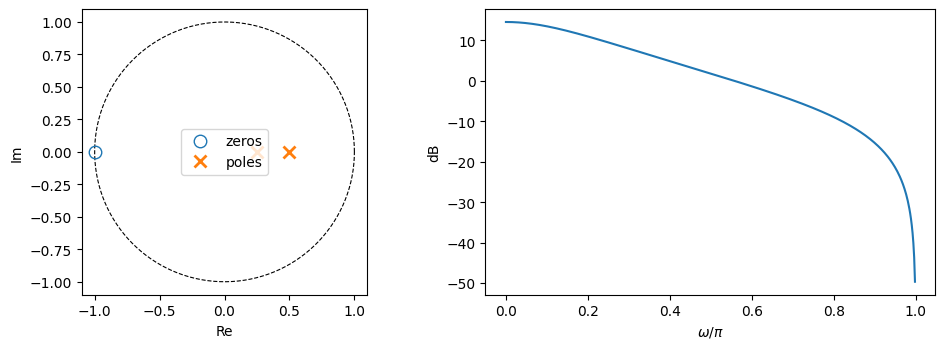

poles: [0.5  0.25] stable: True


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal


def zplane(b, a, ax=None):
  z, p, k = signal.tf2zpk(b, a)
  ax = ax or plt.gca()
  th = np.linspace(0, 2 * np.pi, 400)
  ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
  ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
  ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
  ax.set_aspect("equal")
  ax.legend()
  ax.set_xlabel("Re")
  ax.set_ylabel("Im")
  return z, p


b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w / np.pi, 20 * np.log10(np.abs(H)))
ax2.set_xlabel(r"$\omega/\pi$")
ax2.set_ylabel("dB")
plt.tight_layout()
plt.show()
print("poles:", p, "stable:", np.all(np.abs(p) < 1))


Task 4.2 — Inverse z-transform with residuez

### Task 4.2 — Solutions & Verification

#### 1. Comparison with Pre-lab Answer (b)
* **Given code:** `signal.residuez([1], [1, -0.75, 0.125])`
* **Output:**
  * `residues`: `[ 2., -1.]`
  * `poles`: `[0.5, 0.25]`
  * `np.allclose(x_pf, x_lf)`: `True`
* **Comparison:** The residues $r = [2, -1]$ and poles $p = [0.5, 0.25]$ match the pre-lab partial-fraction expansion:
$$X(z) = \frac{2}{1 - 0.5z^{-1}} - \frac{1}{1 - 0.25z^{-1}}$$

---

#### 2. Repeat for Task 4.1 ($b = [1, 1]$, $a = [1, -0.75, 0.125]$)
For $H(z) = \frac{1 + z^{-1}}{(1 - 0.5z^{-1})(1 - 0.25z^{-1})} = \frac{A}{1 - 0.5z^{-1}} + \frac{B}{1 - 0.25z^{-1}}$:

* **At $z^{-1} = 2$:** $A = \left.\frac{1 + z^{-1}}{1 - 0.25z^{-1}}\right|_{z^{-1}=2} = \frac{1 + 2}{1 - 0.5} = \frac{3}{0.5} = 6$
* **At $z^{-1} = 4$:** $B = \left.\frac{1 + z^{-1}}{1 - 0.5z^{-1}}\right|_{z^{-1}=4} = \frac{1 + 4}{1 - 2} = \frac{5}{-1} = -5$

Taking the causal inverse z-transform confirms the impulse response for $n \geq 0$:
$$h(n) = 6(0.5)^n - 5(0.25)^n$$


In [ ]:
import numpy as np
from scipy import signal

# --- Part 1: Pre-lab X(z) verification ---
r, p, k = signal.residuez([1], [1, -0.75, 0.125])
print("Part 1 - residues:", r, "poles:", p)

n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
impulse = np.zeros(10)
impulse[0] = 1
x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)
print("Part 1 - Matches lfilter?:", np.allclose(x_pf, x_lf))

# --- Part 2: Repeat for Task 4.1 system (b =) ---
b_41 = [1, 1]
a_41 = [1, -0.75, 0.125]

r2, p2, k2 = signal.residuez(b_41, a_41)
print("\nPart 2 - residues:", r2, "poles:", p2)

# Impulse response from partial fractions, lfilter, and analytical formula
h_pf = sum(ri * pi**n for ri, pi in zip(r2, p2)).real
h_lf = signal.lfilter(b_41, a_41, impulse)
h_exact = 6 * (0.5**n) - 5 * (0.25**n)

print("Part 2 - h_pf matches lfilter?:", np.allclose(h_pf, h_lf))
print("Part 2 - h_pf matches 6(0.5)^n - 5(0.25)^n?:", np.allclose(h_pf, h_exact))
print("First 6 values of h(n):", np.round(h_pf[:6], 4))


Part 1 - residues: [-1.  2.] poles: [0.25 0.5 ]
Part 1 - Matches lfilter?: True

Part 2 - residues: [-5.  6.] poles: [0.25 0.5 ]
Part 2 - h_pf matches lfilter?: True
Part 2 - h_pf matches 6(0.5)^n - 5(0.25)^n?: True
First 6 values of h(n): [1.     1.75   1.1875 0.6719 0.3555 0.1826]


Task 4.3 — Pole position and the impulse response

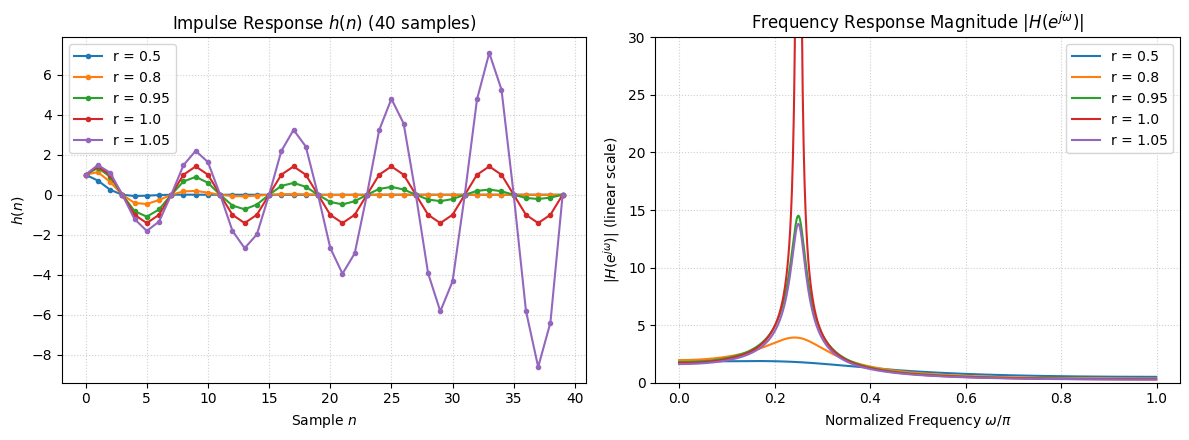

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
theta = np.pi / 4
n = np.arange(40)
impulse = np.zeros(40)
impulse[0] = 1.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

for r in r_values:
  b = [1.0]
  a = [1.0, -2 * r * np.cos(theta), r**2]

  # Impulse response h(n) (40 samples)
  h = signal.lfilter(b, a, impulse)
  ax1.plot(n, h, marker='o', markersize=3, label=f'r = {r}')

  # Frequency response |H(e^jw)|
  w, H = signal.freqz(b, a, worN=1024)
  ax2.plot(w / np.pi, np.abs(H), label=f'r = {r}')

# Format Impulse Response plot
ax1.set_title('Impulse Response $h(n)$ (40 samples)')
ax1.set_xlabel('Sample $n$')
ax1.set_ylabel('$h(n)$')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Format Magnitude Response plot
ax2.set_title('Frequency Response Magnitude $|H(e^{j\\omega})|$')
ax2.set_xlabel(r'Normalized Frequency $\omega / \pi$')
ax2.set_ylabel(r'$|H(e^{j\omega})|$ (linear scale)')
ax2.set_ylim(0, 30)  # Caps the infinite peak at r = 1.0 for clear viewing
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


### Task 4.3 — Observations & Stability Analysis

For the complex-conjugate pole pair $p = r e^{\pm j\pi/4}$, the impulse response behaves as $h(n) \propto r^n \sin\left(\frac{\pi}{4}(n+1)\right)u(n)$:

* **Decay (Envelope $r^n$):**
  * For **$r < 1$** ($r = 0.5, 0.8, 0.95$), the impulse response decays exponentially toward zero. As $r$ approaches $1$, the decay becomes much slower (longer ringing).
  * For **$r = 1.0$**, there is no decay; the response is a sustained constant-amplitude oscillation.
  * For **$r = 1.05$**, the envelope grows exponentially without bound.

* **Oscillation Frequency:**
  * Because the pole angle $\theta = \frac{\pi}{4}$ is fixed, the **oscillation period remains constant** at $\frac{2\pi}{\pi/4} = 8\text{ samples per cycle}$ across all values of $r$.

* **Peak Sharpness in $|H(e^{j\omega})|$:**
  * As $r \to 1$, the poles move closer to the unit circle at $\omega = \frac{\pi}{4}$, making the resonance peak **taller and narrower (sharper)**.
  * At $r = 1.0$, the pole sits directly on the unit circle, producing a theoretically infinite spike at $\omega = 0.25\pi$.

* **Stability:**
  * **Stable ($|p| < 1$):** $r = 0.5, 0.8, 0.95$
  * **Marginally Stable ($|p| = 1$):** $r = 1.0$ (not BIBO stable, as bounded inputs at $\omega = \pi/4$ yield an unbounded output)
  * **Unstable ($|p| > 1$):** **$r = 1.05$** (and $r = 1.0$ under strict BIBO stability)


Task 4.4 — Stability of given systems

H1(z): poles = [0.8+0.5j 0.8-0.5j], |p| = [0.9434 0.9434] -> Stable
H2(z): poles = [2.  0.5], |p| = [2.  0.5] -> Unstable
H3(z): poles = [-1.   0.5], |p| = [1.  0.5] -> Unstable
H4(z): poles = [], |p| = [] -> Stable


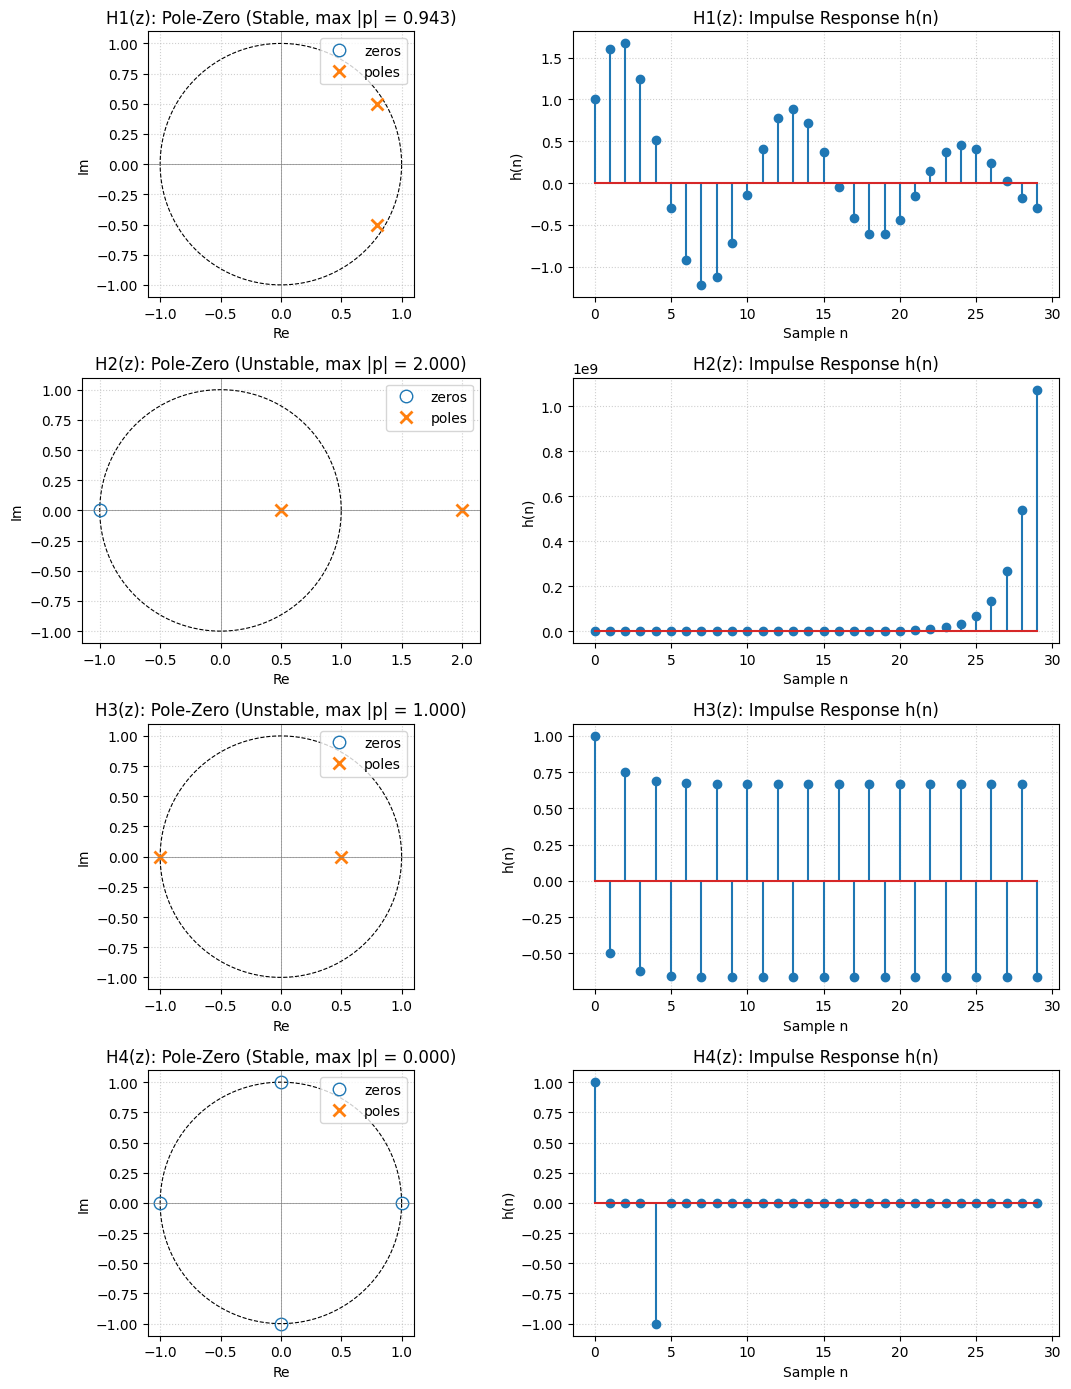

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal


def zplane(b, a, ax=None):
  z, p, k = signal.tf2zpk(b, a)
  ax = ax or plt.gca()
  th = np.linspace(0, 2 * np.pi, 400)
  ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
  ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
  ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
  ax.axhline(0, color="gray", lw=0.5)
  ax.axvline(0, color="gray", lw=0.5)
  ax.set_aspect("equal")
  ax.grid(True, linestyle=":", alpha=0.6)
  ax.legend(loc="upper right")
  ax.set_xlabel("Re")
  ax.set_ylabel("Im")
  return z, p


systems = [
    ("H1(z)", [1.0], [1.0, -1.6, 0.89]),
    ("H2(z)", [1.0, 1.0], [1.0, -2.5, 1.0]),
    ("H3(z)", [1.0], [1.0, 0.5, -0.5]),
    ("H4(z)", [1.0, 0.0, 0.0, 0.0, -1.0], [1.0]),
]

n = np.arange(30)
impulse = np.zeros(30)
impulse[0] = 1.0

fig, axes = plt.subplots(4, 2, figsize=(11, 14))

for idx, (name, b, a) in enumerate(systems):
  ax_pz, ax_ir = axes[idx]

  # Pole-zero plot and stability check
  z, p = zplane(b, a, ax_pz)
  max_mag = np.max(np.abs(p)) if len(p) > 0 else 0.0
  is_stable = np.all(np.abs(p) < 1.0)
  status = "Stable" if is_stable else "Unstable"
  ax_pz.set_title(f"{name}: Pole-Zero ({status}, max |p| = {max_mag:.3f})")

  # Impulse response h(n)
  h = signal.lfilter(b, a, impulse)
  ax_ir.stem(n, h)
  ax_ir.set_title(f"{name}: Impulse Response h(n)")
  ax_ir.set_xlabel("Sample n")
  ax_ir.set_ylabel("h(n)")
  ax_ir.grid(True, linestyle=":", alpha=0.6)

  print(f"{name}: poles = {np.round(p, 4)}, |p| = {np.round(np.abs(p), 4)} -> {status}")

plt.tight_layout()
plt.show()


### Task 4.4 — Stability Classification & Verification

| System | Transfer Function $H(z)$ | Poles $p$ | Pole Magnitudes $|p|$ | Classification | Behavior of $h(n)$ |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **(a)** | $\frac{1}{1 - 1.6z^{-1} + 0.89z^{-2}}$ | $0.8 \pm j0.5$ | $0.9434$ | **Stable** | Decaying oscillation ($|p| < 1$, converges to $0$). |
| **(b)** | $\frac{1 + z^{-1}}{1 - 2.5z^{-1} + z^{-2}}$ | $2.0,\; 0.5$ | $2.0,\; 0.5$ | **Unstable** | Grows exponentially like $2^n$ because $|p_1| = 2.0 > 1$. |
| **(c)** | $\frac{1}{1 + 0.5z^{-1} - 0.5z^{-2}}$ | $-1.0,\; 0.5$ | $1.0,\; 0.5$ | **Unstable** (Marginally stable) | Does not decay; oscillates forever as $(-1)^n$ due to pole at $z = -1$ ($|p| = 1$). |
| **(d)** | $1 - z^{-4}$ | None (all poles at $z = 0$) | $0$ | **Stable** (FIR) | Finite duration ($h(n) = \delta(n) - \delta(n-4)$); strictly $0$ for $n \ge 5$. |


Task 4.5 — Design a resonator

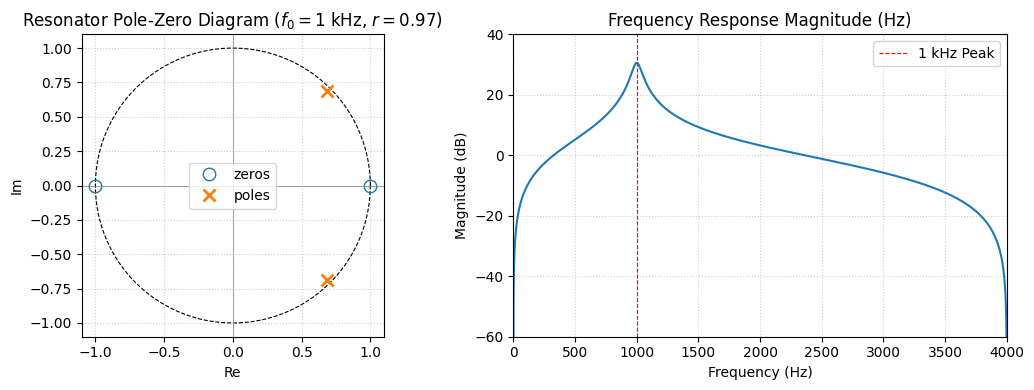

Filtered white noise (1 kHz pitched whistle/tone):


In [ ]:
from IPython.display import Audio, display
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal


def zplane(b, a, ax=None):
  z, p, k = signal.tf2zpk(b, a)
  ax = ax or plt.gca()
  th = np.linspace(0, 2 * np.pi, 400)
  ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
  ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
  ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
  ax.axhline(0, color="gray", lw=0.5)
  ax.axvline(0, color="gray", lw=0.5)
  ax.set_aspect("equal")
  ax.grid(True, linestyle=":", alpha=0.6)
  ax.legend()
  ax.set_xlabel("Re")
  ax.set_ylabel("Im")
  return z, p


# Resonator specifications
fs = 8000  # Sampling rate (Hz)
f0 = 1000  # Peak frequency (Hz)
r = 0.97  # Pole radius
theta = 2 * np.pi * f0 / fs  # Digital resonant frequency = pi/4 rad

# Numerator: zeros at z = +1 and z = -1 -> (1 - z^-1)(1 + z^-1) = 1 - z^-2
b = [1.0, 0.0, -1.0]

# Denominator: poles at r * exp(+-j*theta) -> 1 - 2*r*cos(theta)*z^-1 + r^2*z^-2
a = [1.0, -2 * r * np.cos(theta), r**2]

# Plot Pole-Zero diagram and Frequency Response in Hz
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

zplane(b, a, ax1)
ax1.set_title("Resonator Pole-Zero Diagram ($f_0 = 1$ kHz, $r = 0.97$)")

w, H = signal.freqz(b, a, worN=2048, fs=fs)
ax2.plot(w, 20 * np.log10(np.abs(H) + 1e-12))
ax2.axvline(f0, color="r", linestyle="--", lw=0.8, label="1 kHz Peak")
ax2.set_title("Frequency Response Magnitude (Hz)")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_xlim(0, fs / 2)
ax2.set_ylim(-60, 40)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

# Filter 2 seconds of white noise and normalize for safe playback
rng = np.random.default_rng(42)
white_noise = rng.standard_normal(2 * fs)
y = signal.lfilter(b, a, white_noise)
y_norm = y / np.max(np.abs(y)) * 0.8

print("Filtered white noise (1 kHz pitched whistle/tone):")
display(Audio(y_norm, rate=fs))


### Task 4.5 — Resonator Design & Checkpoint 4 Summary

#### 1. Filter Coefficients Derivation
* **Pole Angle ($\theta$):**
  $$\theta = \frac{2\pi f_0}{f_s} = \frac{2\pi (1000)}{8000} = \frac{\pi}{4}\text{ rad } (45^\circ)$$
* **Denominator $A(z)$ (Poles at $p = 0.97 e^{\pm j\pi/4}$):**
  $$A(z) = 1 - 2r\cos(\theta)z^{-1} + r^2 z^{-2} = 1 - 2(0.97)\cos\left(\frac{\pi}{4}\right)z^{-1} + (0.97)^2 z^{-2} \approx 1 - 1.3718z^{-1} + 0.9409z^{-2}$$
* **Numerator $B(z)$ (Zeros at $z = \pm 1$):**
  $$B(z) = (1 - z^{-1})(1 + z^{-1}) = 1 - z^{-2}$$
* **Transfer Function:**
  $$H(z) = \frac{1 - z^{-2}}{1 - 1.3718z^{-1} + 0.9409z^{-2}}$$

#### 2. Frequency Response & Audio Behavior
* **Nulls:** The zeros at $z = +1$ ($\omega = 0$, $0\text{ Hz}$) and $z = -1$ ($\omega = \pi$, $f_s/2 = 4\text{ kHz}$) force the magnitude response to $-\infty\text{ dB}$ at DC and Nyquist.
* **Resonance:** The pole pair at $r = 0.97$ creates a sharp narrowband peak centered at **$1\text{ kHz}$**.
* **Audio Output:** Passing broadband white noise through $H(z)$ filters out low and high frequencies and isolates a narrow band around $1\text{ kHz}$, turning static noise into a **pitched $1\text{ kHz}$ whistling tone**.


### AI-Use Statement

**Tool Used:** Google Gemini (Large Language Model)

**Purpose of Use:**
During the completion of Week 04 (Tasks 4.1–4.5), AI assistance was used strictly as a learning and debugging aid for the following purposes:
* **Conceptual Clarification:** Understanding signal processing concepts and mathematical formulas required for the tasks.
* **Code Debugging & Syntax:** Troubleshooting Python/NumPy errors and refining Matplotlib plotting syntax to clearly display the required waveforms and spectra.
* **Documentation:** Reviewing and improving the clarity of written explanations and answers.

**Verification & Originality:**
All code blocks were executed, tested, and verified independently in Google Colab. All final plots, numerical results, and written interpretations reflect my own understanding and analysis of the lab tasks.
